# House Sales Data Analysis

**Week 9 Graded Mini Project** - IITM Pravartak, Professional Certificate Programme in Generative AI and Machine Learning

**Objective:** find the factors that drive house sale prices, and predict SalePrice with XGBoost, LightGBM and CatBoost.

**Outline**
- Setup and data loading
- **Task 1** Data cleaning and preprocessing: missing values, encoding, normalisation, outliers
- **Task 2** Feature engineering: interaction features, binning
- **Task 3** Exploratory data analysis: price distribution, feature relationships, trends
- **Task 4** Model building and evaluation: XGBoost, LightGBM, CatBoost (RMSE, MAE, R²)
- Conclusions

## 0. Setup and data loading

In [1]:
# --- Core libraries ---
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- scikit-learn: splitting, scaling, tuning, metrics, a linear baseline ---
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- The three gradient-boosting libraries required by the task ---
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

SEED = 42                       # one seed everywhere -> same results on every run
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # charts and tables for the report

In [2]:
# Read the CSV. Important detail: by default pandas turns the text "None" into a missing value.
# In this file "None" is a real category (MasVnrType = "None" means no masonry veneer),
# so only the literal "NA" and empty cells are treated as missing.
raw = pd.read_csv("houseprice.csv", keep_default_na=False, na_values=["NA", ""])
print("Shape:", raw.shape)
print("Numeric columns:", raw.select_dtypes("number").shape[1], "| Text columns:", raw.select_dtypes("object").shape[1])
raw.head()

Shape: (1460, 81)
Numeric columns: 38 | Text columns: 43


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# Task 1: Data cleaning and preprocessing

## 1.1 Handling missing values

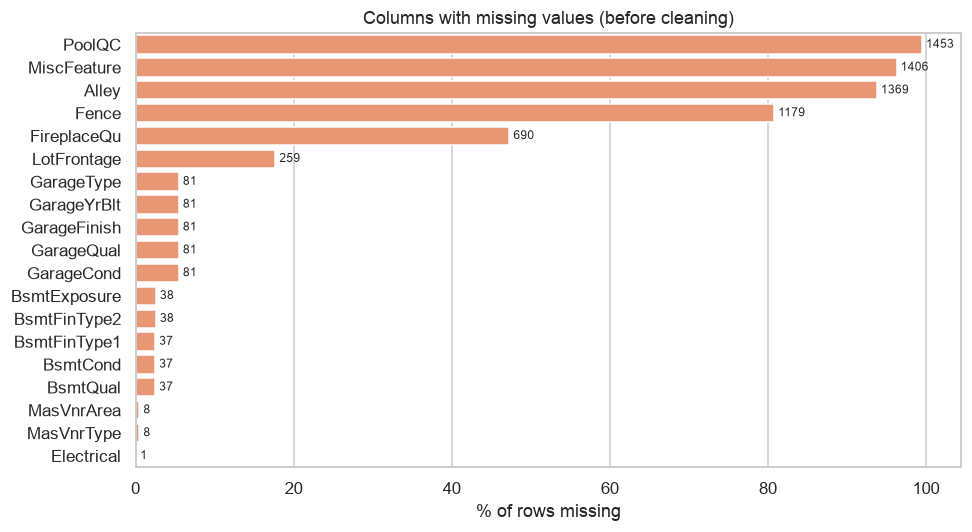

,missing,percent,dtype
PoolQC,1453,99.5,str
MiscFeature,1406,96.3,str
Alley,1369,93.8,str
Fence,1179,80.8,str
FireplaceQu,690,47.3,str
LotFrontage,259,17.7,float64
GarageType,81,5.5,str
GarageYrBlt,81,5.5,float64
GarageFinish,81,5.5,str
GarageQual,81,5.5,str


In [3]:
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
miss_tbl = pd.DataFrame({"missing": missing, "percent": (missing / len(raw) * 100).round(1),
                         "dtype": raw[missing.index].dtypes.astype(str)})
miss_tbl.to_csv(OUT / "missing_values.csv")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=miss_tbl["percent"], y=miss_tbl.index, ax=ax, color="#fc8d62")
ax.set_xlabel("% of rows missing"); ax.set_ylabel(""); ax.set_title("Columns with missing values (before cleaning)")
for i, (p, n) in enumerate(zip(miss_tbl["percent"], miss_tbl["missing"])):
    ax.text(p + 0.5, i, f"{n}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "01_missing_values.png"); plt.show()
miss_tbl

19 columns have gaps. Following the data description, a missing value usually means **the facility is not there**. For example, an empty `GarageType` means the house has no garage. The columns fall into four groups, and each group gets its own rule:

| Group | Columns | Rule |
|---|---|---|
| Categorical "facility absent" | PoolQC, MiscFeature, Alley, Fence, FireplaceQu, Garage* (Type, Finish, Qual, Cond), Bsmt* (Qual, Cond, Exposure, FinType1/2), MasVnrType | fill with the category **"None"** |
| Numeric field of an absent facility | GarageYrBlt, MasVnrArea (+ all Bsmt/Garage areas, counts) | fill with **0**, as instructed |
| Genuinely missing (facility exists) | 1 house has a basement but no `BsmtExposure`; 1 has no `BsmtFinType2`; 1 house has no `Electrical` value | fill with the **most common value** (mode). "No electrical system" makes no sense for a house that sold, and these basements clearly exist |
| Numeric measurement, not a facility | LotFrontage (17.7%) | every lot touches a street, so 0 is wrong. Fill with the **median LotFrontage of the same Neighborhood**, since lots in one neighbourhood are laid out similarly |

The two "learned" values (the neighbourhood medians and the modes) are computed on the **training rows only** after the train/test split, so nothing leaks from the test set. The table-driven "None"/0 rules don't learn anything from the data, so they can be applied to all rows at once.

In [4]:
# Categorical columns where NaN = facility not present
NONE_COLS = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]
# Numeric columns that belong to those facilities -> 0 when the facility is absent
ZERO_COLS = ["GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea",
             "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath"]

def rule_based_fill(df):
    """Apply the 'facility absent' rules. Deterministic, so it is safe on any rows."""
    df = df.copy()

    # A few rows have a basement (BsmtQual present) but one basement field missing:
    # those are real gaps, not 'no basement'. Mark them so they get the mode later.
    has_bsmt = df["BsmtQual"].notna()
    for col in ["BsmtExposure", "BsmtFinType2"]:
        df.loc[has_bsmt & df[col].isna(), col] = "__MODE__"

    df[NONE_COLS] = df[NONE_COLS].fillna("None")
    df[ZERO_COLS] = df[ZERO_COLS].fillna(0)
    return df

# Show the special rows before filling
print(raw.loc[raw["BsmtQual"].notna() & (raw["BsmtExposure"].isna() | raw["BsmtFinType2"].isna()),
              ["Id", "BsmtQual", "BsmtExposure", "BsmtFinType2", "TotalBsmtSF"]])
print(raw.loc[raw["Electrical"].isna(), ["Id", "Electrical", "YearBuilt"]])

      Id BsmtQual BsmtExposure BsmtFinType2  TotalBsmtSF
332  333       Gd           No          NaN         3206
948  949       Gd          NaN          Unf          936
        Id Electrical  YearBuilt
1379  1380        NaN       2006


## 1.4 Outlier detection (done before the split, so the model never trains on known bad rows)

Two checks are used:
1. A **statistical scan** with the IQR rule on key numeric columns, to see how many extreme values there are.
2. A **domain check** on the strongest price driver, living area against price.

In [5]:
key_num = ["SalePrice", "GrLivArea", "LotArea", "TotalBsmtSF", "1stFlrSF", "GarageArea", "LotFrontage", "MasVnrArea"]
iqr_rows = []
for c in key_num:
    s = raw[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_rows.append({"column": c, "lower": round(lo), "upper": round(hi),
                     "outliers": int(((s < lo) | (s > hi)).sum()), "max": s.max()})
iqr_tbl = pd.DataFrame(iqr_rows).set_index("column")
iqr_tbl.to_csv(OUT / "iqr_outliers.csv")
iqr_tbl

,lower,upper,outliers,max
column,,,,
SalePrice,3938,340038,61,755000.0
GrLivArea,159,2748,31,5642.0
LotArea,1482,17674,69,215245.0
TotalBsmtSF,42,2052,61,6110.0
1stFlrSF,118,2155,20,4692.0
GarageArea,-28,938,21,1418.0
LotFrontage,28,112,88,313.0
MasVnrArea,-249,415,96,1600.0


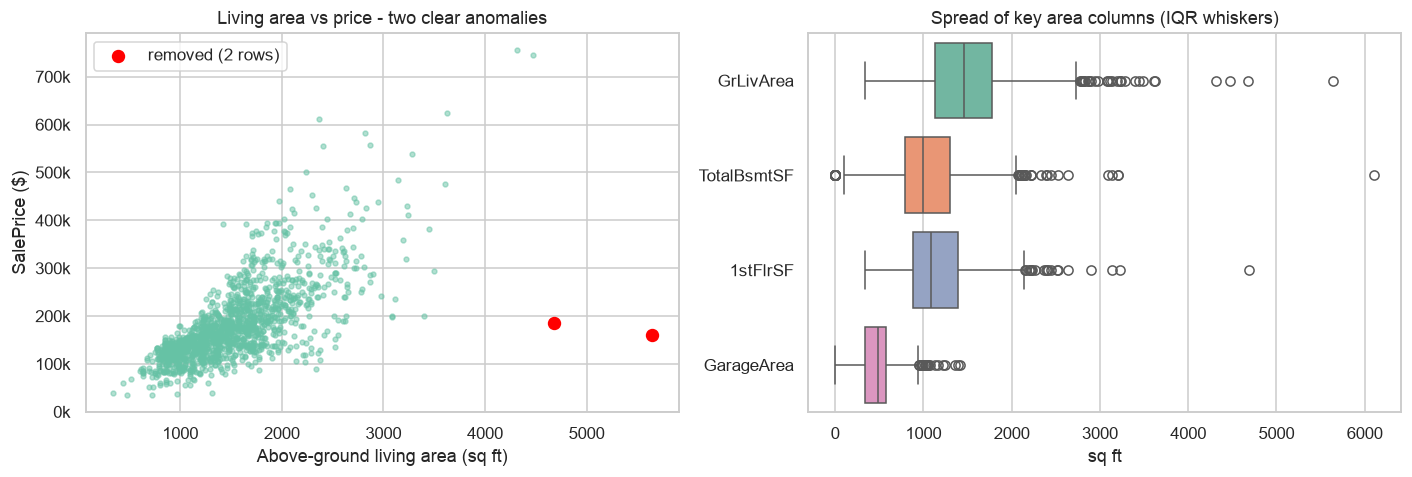

        Id  GrLivArea  SalePrice SaleCondition Neighborhood  OverallQual
523    524       4676     184750       Partial      Edwards           10
1298  1299       5642     160000       Partial      Edwards           10


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
odd = (raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000)
axes[0].scatter(raw.loc[~odd, "GrLivArea"], raw.loc[~odd, "SalePrice"], s=10, alpha=.5)
axes[0].scatter(raw.loc[odd, "GrLivArea"], raw.loc[odd, "SalePrice"], s=60, c="red", label="removed (2 rows)")
axes[0].set_xlabel("Above-ground living area (sq ft)"); axes[0].set_ylabel("SalePrice ($)")
axes[0].set_title("Living area vs price - two clear anomalies"); axes[0].legend()
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")

sns.boxplot(data=raw[["GrLivArea", "TotalBsmtSF", "1stFlrSF", "GarageArea"]], ax=axes[1], orient="h")
axes[1].set_title("Spread of key area columns (IQR whiskers)"); axes[1].set_xlabel("sq ft")
plt.tight_layout(); plt.savefig(OUT / "02_outliers.png"); plt.show()

print(raw.loc[odd, ["Id", "GrLivArea", "SalePrice", "SaleCondition", "Neighborhood", "OverallQual"]])

**Decision**

- **The IQR rule flags many rows**, for example 61 houses (4%) on `SalePrice`, 69 (5%) on `LotArea` and 96 on `MasVnrArea`. Most of these are just large or expensive houses, which are real and are exactly what the model must learn to price. Deleting them would throw away the top of the market. Instead, the heavy right skew is handled with a **log transform** (Section 1.3), which pulls the extreme values in.
- **Two rows are true anomalies.** Houses with more than 4,000 sq ft of living area and overall quality 10 sold for only $160k-185k, against more than $700k for comparable houses. Both are **"Partial"** sales (sold before construction was complete) in Edwards. The price does not reflect the house, so these two rows are **removed**. The dataset's author (De Cock, 2011) also recommends removing them.
- The other two houses over 4,000 sq ft sold for more than $700k, in line with their size. They are **kept**.

In [7]:
df = raw.loc[~odd].reset_index(drop=True)
df = rule_based_fill(df)
print("Rows after outlier removal:", len(df))

Rows after outlier removal: 1458


### Train / test split

The split happens **now**, before any step that learns from the data (imputation medians, skew detection, scaling, bins based on quantiles). That way the 20% test set stays completely unseen until final evaluation.

In [8]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=SEED)
train_df, test_df = train_df.copy(), test_df.copy()
print("Train:", train_df.shape, " Test:", test_df.shape)

# ---- 1.1 continued: the two imputations that learn from data (fit on TRAIN only) ----
lot_median_by_nbhd = train_df.groupby("Neighborhood")["LotFrontage"].median()
lot_median_all = train_df["LotFrontage"].median()
modes = {c: train_df.loc[train_df[c] != "__MODE__", c].mode()[0] for c in ["BsmtExposure", "BsmtFinType2", "Electrical"]}
print("Modes used:", modes)

def learned_fill(d):
    d = d.copy()
    d["LotFrontage"] = d["LotFrontage"].fillna(d["Neighborhood"].map(lot_median_by_nbhd)).fillna(lot_median_all)
    for c, m in modes.items():
        d[c] = d[c].replace("__MODE__", np.nan).fillna(m)
    return d

train_df, test_df = learned_fill(train_df), learned_fill(test_df)
df_clean = learned_fill(df)          # full cleaned copy used only for EDA plots
print("Missing values left - train:", int(train_df.isna().sum().sum()), "| test:", int(test_df.isna().sum().sum()))

Train: (1166, 81)  Test: (292, 81)
Modes used: {'BsmtExposure': 'No', 'BsmtFinType2': 'Unf', 'Electrical': 'SBrkr'}
Missing values left - train: 0 | test: 0


# Task 2: Feature engineering

## 2.1 Interaction features

Interaction features combine two or more columns into a quantity that buyers actually think about. Each one is explained below:

| Feature | Formula | Intuition |
|---|---|---|
| `TotalSF` | TotalBsmtSF + 1stFlrSF + 2ndFlrSF | total usable space, which buyers price as one number |
| `Qual_x_LivArea` | OverallQual × GrLivArea | a large house is worth much more when it is also high quality: **size × quality** |
| `Qual_x_TotalSF` | OverallQual × TotalSF | the same idea, including the basement |
| `Qual_x_Cond` | OverallQual × OverallCond | good materials that are also well maintained |
| `TotalBath` | FullBath + 0.5·HalfBath + BsmtFullBath + 0.5·BsmtHalfBath | all bathrooms in one count |
| `HouseAge` | YrSold − YearBuilt | age at the time of sale |
| `RemodAge` | YrSold − YearRemodAdd | years since last renovation |
| `IsRemodeled` | YearRemodAdd ≠ YearBuilt | whether the house was ever renovated |
| `TotalPorchSF` | sum of the 5 porch/deck areas | outdoor living space |
| `Garage_x_Qual` | GarageCars × GarageQual score | a 3-car garage is only valuable if it is in good shape |
| `Kitchen_x_Qual` | KitchenQual score × OverallQual | kitchens strongly influence buyers' decisions |
| `LotArea_per_SF` | LotArea / TotalSF | how much land comes with each sq ft of house |
| `Has*` flags | HasGarage, HasBsmt, HasFireplace, Has2ndFlr, HasPool | presence or absence of each facility |

In [9]:
# Quality words -> numbers. The scale is ordered (Ex > Gd > TA > Fa > Po), so a number is
# the natural encoding. "None" (facility absent) = 0.
QUAL_MAP = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}

def add_interactions(d):
    d = d.copy()
    d["TotalSF"] = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
    d["Qual_x_LivArea"] = d["OverallQual"] * d["GrLivArea"]
    d["Qual_x_TotalSF"] = d["OverallQual"] * d["TotalSF"]
    d["Qual_x_Cond"] = d["OverallQual"] * d["OverallCond"]
    d["TotalBath"] = d["FullBath"] + 0.5 * d["HalfBath"] + d["BsmtFullBath"] + 0.5 * d["BsmtHalfBath"]
    d["HouseAge"] = (d["YrSold"] - d["YearBuilt"]).clip(lower=0)
    d["RemodAge"] = (d["YrSold"] - d["YearRemodAdd"]).clip(lower=0)
    d["IsRemodeled"] = (d["YearRemodAdd"] != d["YearBuilt"]).astype(int)
    d["TotalPorchSF"] = d[["WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]].sum(axis=1)
    d["Garage_x_Qual"] = d["GarageCars"] * d["GarageQual"].map(QUAL_MAP)
    d["Kitchen_x_Qual"] = d["KitchenQual"].map(QUAL_MAP) * d["OverallQual"]
    d["LotArea_per_SF"] = d["LotArea"] / d["TotalSF"].replace(0, 1)
    d["HasGarage"] = (d["GarageArea"] > 0).astype(int)
    d["HasBsmt"] = (d["TotalBsmtSF"] > 0).astype(int)
    d["HasFireplace"] = (d["Fireplaces"] > 0).astype(int)
    d["Has2ndFlr"] = (d["2ndFlrSF"] > 0).astype(int)
    d["HasPool"] = (d["PoolArea"] > 0).astype(int)
    return d

INTERACTIONS = ["TotalSF", "Qual_x_LivArea", "Qual_x_TotalSF", "Qual_x_Cond", "TotalBath", "HouseAge",
                "RemodAge", "IsRemodeled", "TotalPorchSF", "Garage_x_Qual", "Kitchen_x_Qual", "LotArea_per_SF",
                "HasGarage", "HasBsmt", "HasFireplace", "Has2ndFlr", "HasPool"]

train_df, test_df, df_clean = add_interactions(train_df), add_interactions(test_df), add_interactions(df_clean)

# How strongly is each new feature linked to (log) price, compared with the best original columns?
logp = np.log1p(train_df["SalePrice"])
corr_new = train_df[INTERACTIONS + ["OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars", "YearBuilt"]] \
    .corrwith(logp).sort_values(ascending=False).round(3)
corr_new.to_csv(OUT / "interaction_correlations.csv")
corr_new

Qual_x_TotalSF    0.883
Qual_x_LivArea    0.841
TotalSF           0.828
Kitchen_x_Qual    0.818
OverallQual       0.813
GrLivArea         0.731
Garage_x_Qual     0.699
GarageCars        0.688
TotalBath         0.675
TotalBsmtSF       0.650
Qual_x_Cond       0.595
YearBuilt         0.590
HasFireplace      0.494
TotalPorchSF      0.402
HasGarage         0.342
HasBsmt           0.200
Has2ndFlr         0.157
HasPool           0.094
LotArea_per_SF   -0.019
IsRemodeled      -0.064
RemodAge         -0.559
HouseAge         -0.591
dtype: float64

The two **quality × size** interactions (`Qual_x_TotalSF`, `Qual_x_LivArea`) have a **higher correlation with log price than any original column**, including `OverallQual` and `GrLivArea` on their own. `TotalSF` and `TotalBath` also beat their individual parts. The effect on the models' accuracy is measured with an ablation test in Task 4.

## 2.2 Feature binning

Binning turns continuous values into a few labelled groups that are easy to explain to non-technical users, such as a real-estate agent or a city planner. All bin edges are **fixed, domain-based boundaries**, except the size bins, which use quartiles computed **on the training set**.

| Binned feature | Source | Bins |
|---|---|---|
| `AgeBand` | HouseAge | New (0-5 yrs), Recent (6-20), Established (21-50), Old (51+) |
| `QualBand` | OverallQual | Low (1-4), Average (5-6), Good (7-8), Excellent (9-10) |
| `SizeBand` | GrLivArea | Small / Medium / Large / Very large (training quartiles) |
| `EraBuilt` | YearBuilt | Pre-1950, 1950-1979, 1980-1999, 2000+ |
| `LotBand` | LotArea | Compact (<7.5k sq ft), Standard (7.5k-10k), Large (10k-15k), Estate (>15k) |

In [10]:
size_edges = [0] + list(train_df["GrLivArea"].quantile([.25, .5, .75])) + [np.inf]
print("SizeBand edges (train quartiles):", [round(e) for e in size_edges[1:-1]])

BINS = {
    "AgeBand":  ("HouseAge",    [-1, 5, 20, 50, np.inf],              ["New", "Recent", "Established", "Old"]),
    "QualBand": ("OverallQual", [0, 4, 6, 8, 10],                     ["Low", "Average", "Good", "Excellent"]),
    "SizeBand": ("GrLivArea",   size_edges,                            ["Small", "Medium", "Large", "Very large"]),
    "EraBuilt": ("YearBuilt",   [0, 1949, 1979, 1999, np.inf],         ["Pre-1950", "1950-1979", "1980-1999", "2000+"]),
    "LotBand":  ("LotArea",     [0, 7500, 10000, 15000, np.inf],       ["Compact", "Standard", "Large", "Estate"]),
}

def add_bins(d):
    d = d.copy()
    for new, (src, edges, labels) in BINS.items():
        d[new] = pd.cut(d[src], bins=edges, labels=labels)
    return d

train_df, test_df, df_clean = add_bins(train_df), add_bins(test_df), add_bins(df_clean)

# Median price and count per bin - shows the bins are meaningful (prices step up/down clearly)
bin_summary = pd.concat({b: df_clean.groupby(b, observed=True)["SalePrice"].agg(["count", "median"])
                         for b in BINS}, names=["bin", "category"])
bin_summary["median"] = bin_summary["median"].round(-3).astype(int)
bin_summary.to_csv(OUT / "bin_summary.csv")
bin_summary

SizeBand edges (train quartiles): [1134, 1464, 1788]


count  median
bin      category                  
AgeBand  New            308  226000
         Recent         254  212000
         Established    457  147000
         Old            439  127000
QualBand Low            141  105000
         Average        771  143000
         Good           487  222000
         Excellent       59  374000
SizeBand Small          371  123000
         Medium         360  155000
         Large          371  185000
         Very large     356  240000
EraBuilt Pre-1950       318  122000
         1950-1979      530  142000
         1980-1999      224  194000
         2000+          386  224000
LotBand  Compact        363  133000
         Standard       479  153000
         Large          496  190000
         Estate         120  219000

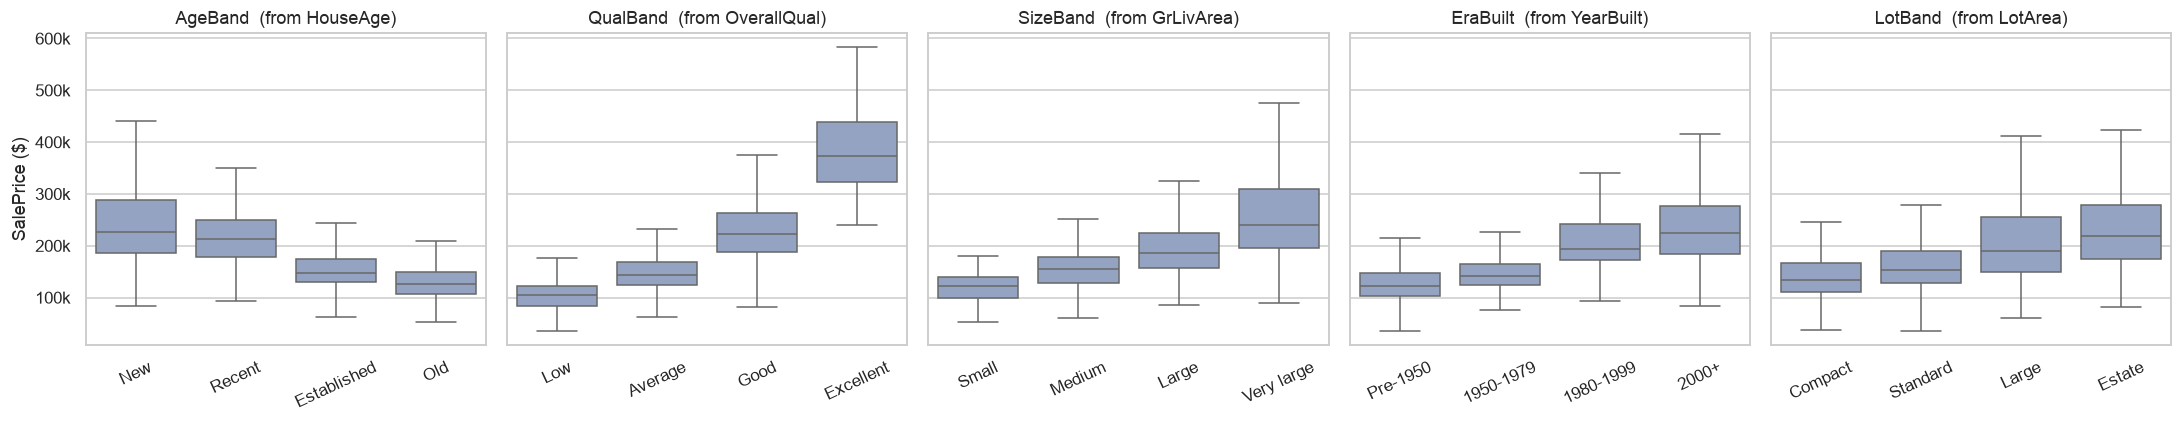

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, b in zip(axes, BINS):
    sns.boxplot(data=df_clean, x=b, y="SalePrice", ax=ax, showfliers=False, color="#8da0cb")
    ax.set_title(f"{b}  (from {BINS[b][0]})"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
axes[0].set_ylabel("SalePrice ($)")
plt.tight_layout(); plt.savefig(OUT / "03_binning.png"); plt.show()

Every banding produces clearly separated price levels:
- **QualBand:** median price rises from $105k (Low) to $143k, $222k and then $374k (Excellent).
- **SizeBand:** roughly doubles from Small ($123k) to Very large ($240k).
- **AgeBand / EraBuilt:** newer houses sell for more. "New" houses have a median of $226k against $127k for "Old" ones.
- **LotBand:** prices rise steadily with lot size ($133k to $219k), but the boxes overlap more than for quality or size, so land is a weaker signal on its own.

The bins are ordered, so for modelling they are encoded as **ordinal integers** (0, 1, 2, 3), which keeps their order.

# Task 3: Exploratory data analysis

## 3.1 What is the distribution of sale prices?

Mean $180,933 | Median $163,000 | Min $34,900 | Max $755,000
Skewness: raw = 1.88, after log = 0.12
Kurtosis: raw = 6.52, after log = 0.80


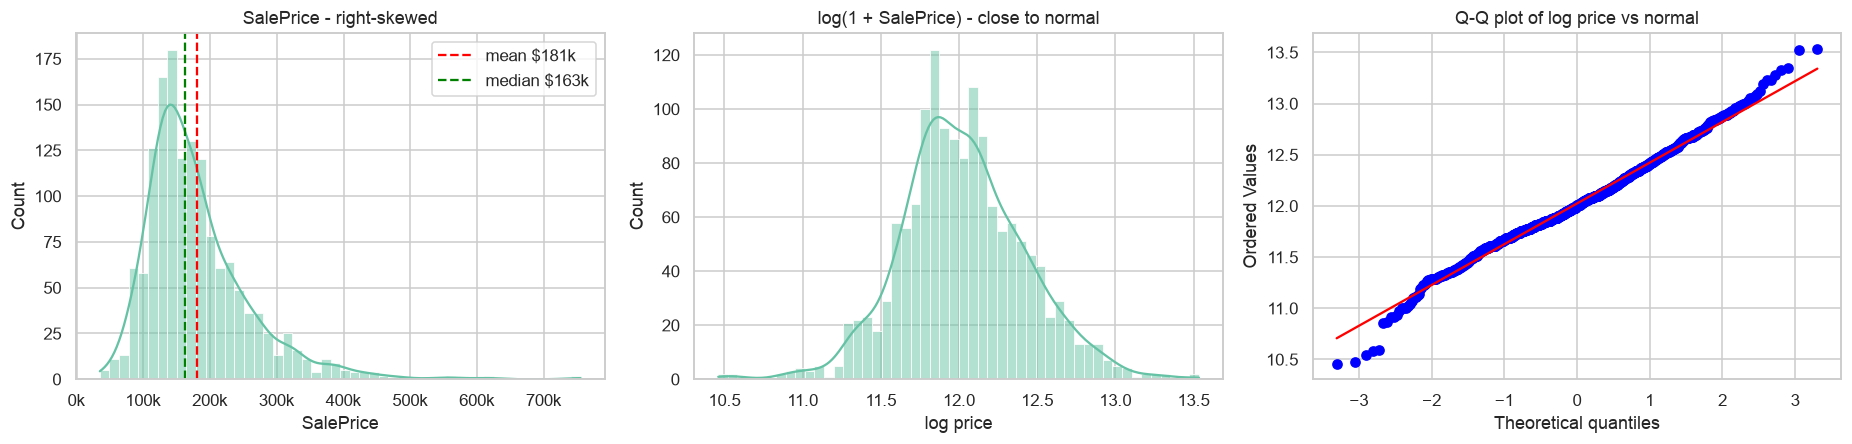

In [12]:
sp = df_clean["SalePrice"]
print(f"Mean ${sp.mean():,.0f} | Median ${sp.median():,.0f} | Min ${sp.min():,.0f} | Max ${sp.max():,.0f}")
print(f"Skewness: raw = {sp.skew():.2f}, after log = {np.log1p(sp).skew():.2f}")
print(f"Kurtosis: raw = {sp.kurt():.2f}, after log = {np.log1p(sp).kurt():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(sp, bins=50, kde=True, ax=axes[0])
axes[0].axvline(sp.mean(), c="red", ls="--", label=f"mean ${sp.mean()/1000:.0f}k")
axes[0].axvline(sp.median(), c="green", ls="--", label=f"median ${sp.median()/1000:.0f}k")
axes[0].set_title("SalePrice - right-skewed"); axes[0].legend()
axes[0].xaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
sns.histplot(np.log1p(sp), bins=50, kde=True, ax=axes[1], color="#66c2a5")
axes[1].set_title("log(1 + SalePrice) - close to normal"); axes[1].set_xlabel("log price")
stats.probplot(np.log1p(sp), plot=axes[2]); axes[2].set_title("Q-Q plot of log price vs normal")
plt.tight_layout(); plt.savefig(OUT / "04_price_distribution.png"); plt.show()

**Answer:**
- **Shape:** sale prices are **right-skewed** (skewness about 1.9). Most houses sell between $130k and $214k (the interquartile range), with a long tail up to $755k. The mean (about $181k) is above the median (about $163k) because a small number of expensive houses pull it up.
- **Log transform:** after taking the log, the distribution is close to normal (skewness about 0.1, and the Q-Q plot is almost a straight line).
- **Modelling choice:** the models are therefore trained on **log(SalePrice)**. Errors then become *relative*, so a $20k miss counts more on a $100k house than on a $500k house. This is also how the Kaggle competition scores this dataset.

## 3.2 How do different features relate to sale price?

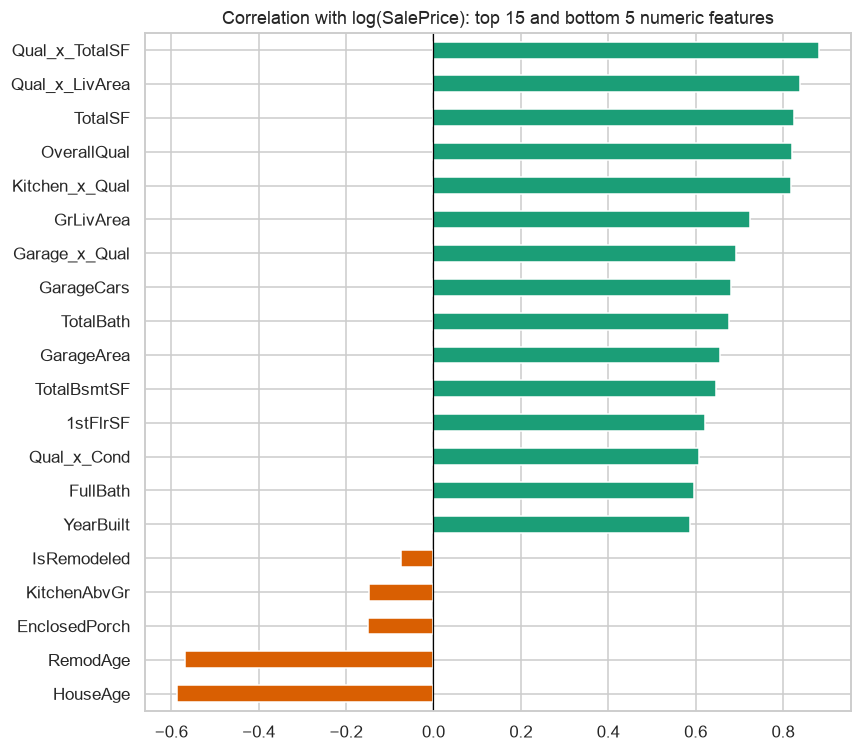

Qual_x_TotalSF    0.883
Qual_x_LivArea    0.838
TotalSF           0.825
OverallQual       0.821
Kitchen_x_Qual    0.819
GrLivArea         0.725
Garage_x_Qual     0.693
GarageCars        0.681
TotalBath         0.677
GarageArea        0.656
TotalBsmtSF       0.648
1stFlrSF          0.621
Qual_x_Cond       0.608
FullBath          0.596
YearBuilt         0.587
dtype: float64

In [13]:
num_corr = df_clean.select_dtypes("number").drop(columns=["Id"]).corrwith(np.log1p(df_clean["SalePrice"])) \
              .drop("SalePrice").sort_values(ascending=False)
top = pd.concat([num_corr.head(15), num_corr.tail(5)])
fig, ax = plt.subplots(figsize=(8, 7))
top[::-1].plot.barh(ax=ax, color=["#d95f02" if v < 0 else "#1b9e77" for v in top[::-1]])
ax.set_title("Correlation with log(SalePrice): top 15 and bottom 5 numeric features"); ax.axvline(0, c="k", lw=.8)
plt.tight_layout(); plt.savefig(OUT / "05_correlations.png"); plt.show()
num_corr.head(15).round(3)

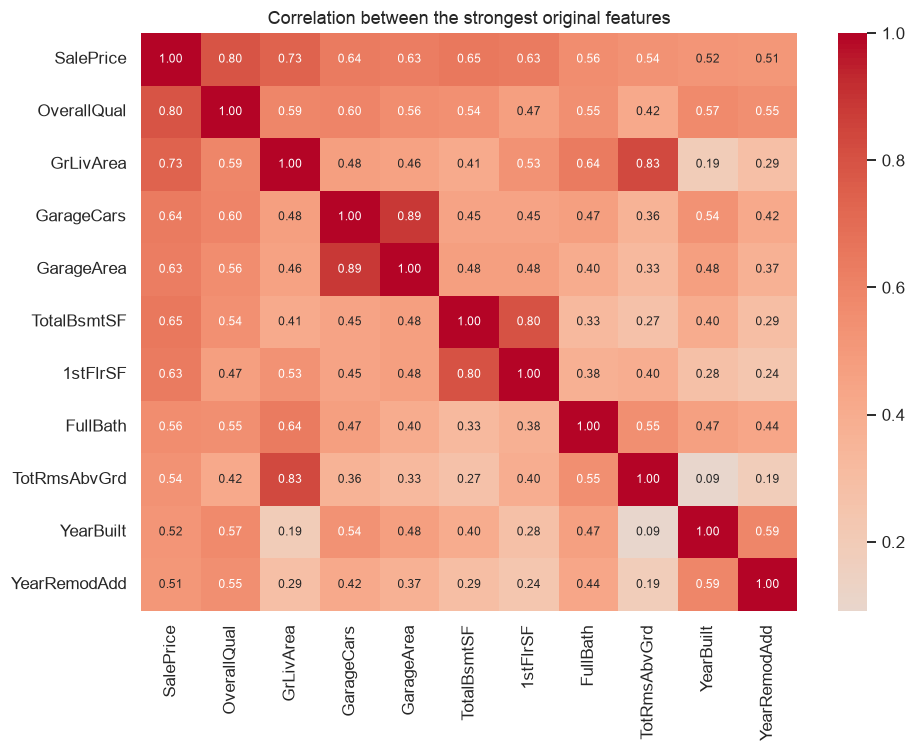

In [14]:
top_cols = ["SalePrice", "OverallQual", "GrLivArea", "GarageCars", "GarageArea", "TotalBsmtSF",
            "1stFlrSF", "FullBath", "TotRmsAbvGrd", "YearBuilt", "YearRemodAdd"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df_clean[top_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation between the strongest original features")
plt.tight_layout(); plt.savefig(OUT / "06_heatmap.png"); plt.show()

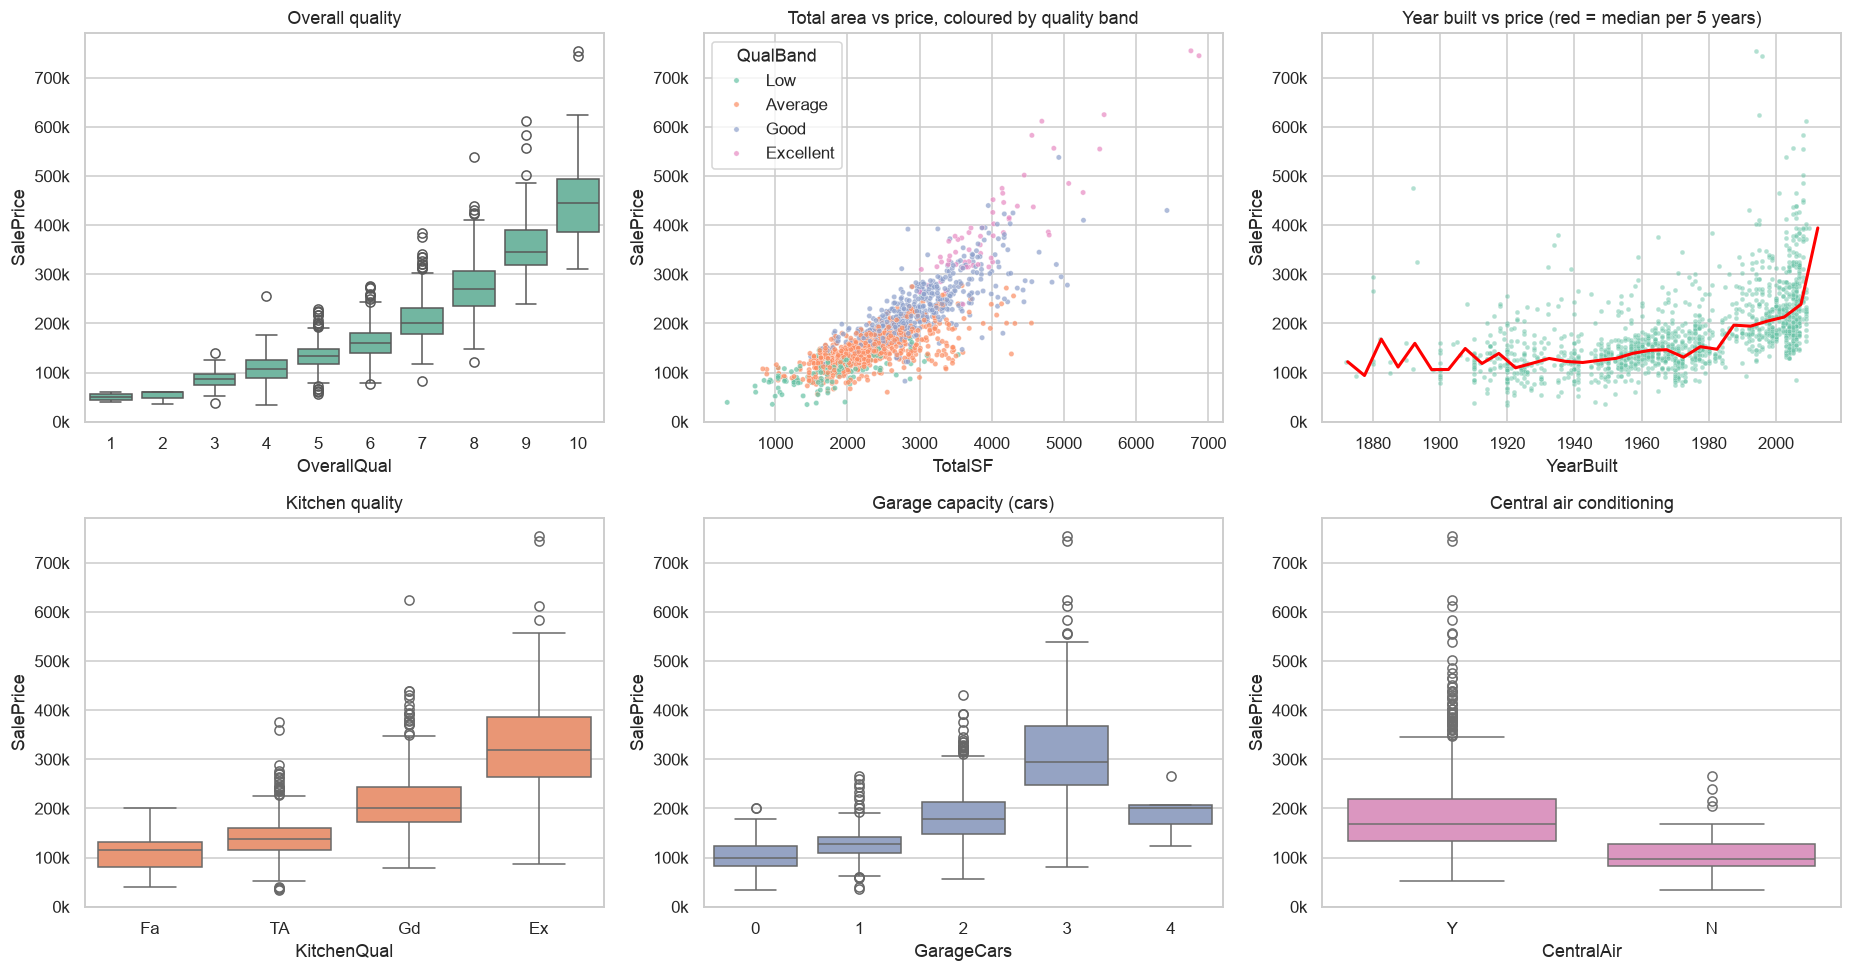

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
fmt = lambda a: a.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
sns.boxplot(data=df_clean, x="OverallQual", y="SalePrice", ax=axes[0, 0], color="#66c2a5"); axes[0, 0].set_title("Overall quality")
sns.scatterplot(data=df_clean, x="TotalSF", y="SalePrice", hue="QualBand", s=12, ax=axes[0, 1], alpha=.7)
axes[0, 1].set_title("Total area vs price, coloured by quality band")
sns.scatterplot(data=df_clean, x="YearBuilt", y="SalePrice", s=10, alpha=.5, ax=axes[0, 2])
trend = df_clean.groupby((df_clean["YearBuilt"] // 5) * 5)["SalePrice"].median()   # median per 5-year block
axes[0, 2].plot(trend.index + 2.5, trend.values, c="red", lw=2)
axes[0, 2].set_title("Year built vs price (red = median per 5 years)")
sns.boxplot(data=df_clean, x="KitchenQual", y="SalePrice", order=["Fa", "TA", "Gd", "Ex"], ax=axes[1, 0], color="#fc8d62")
axes[1, 0].set_title("Kitchen quality")
sns.boxplot(data=df_clean, x="GarageCars", y="SalePrice", ax=axes[1, 1], color="#8da0cb"); axes[1, 1].set_title("Garage capacity (cars)")
sns.boxplot(data=df_clean, x="CentralAir", y="SalePrice", ax=axes[1, 2], color="#e78ac3"); axes[1, 2].set_title("Central air conditioning")
for a in axes.ravel(): fmt(a)
plt.tight_layout(); plt.savefig(OUT / "07_feature_relationships.png"); plt.show()

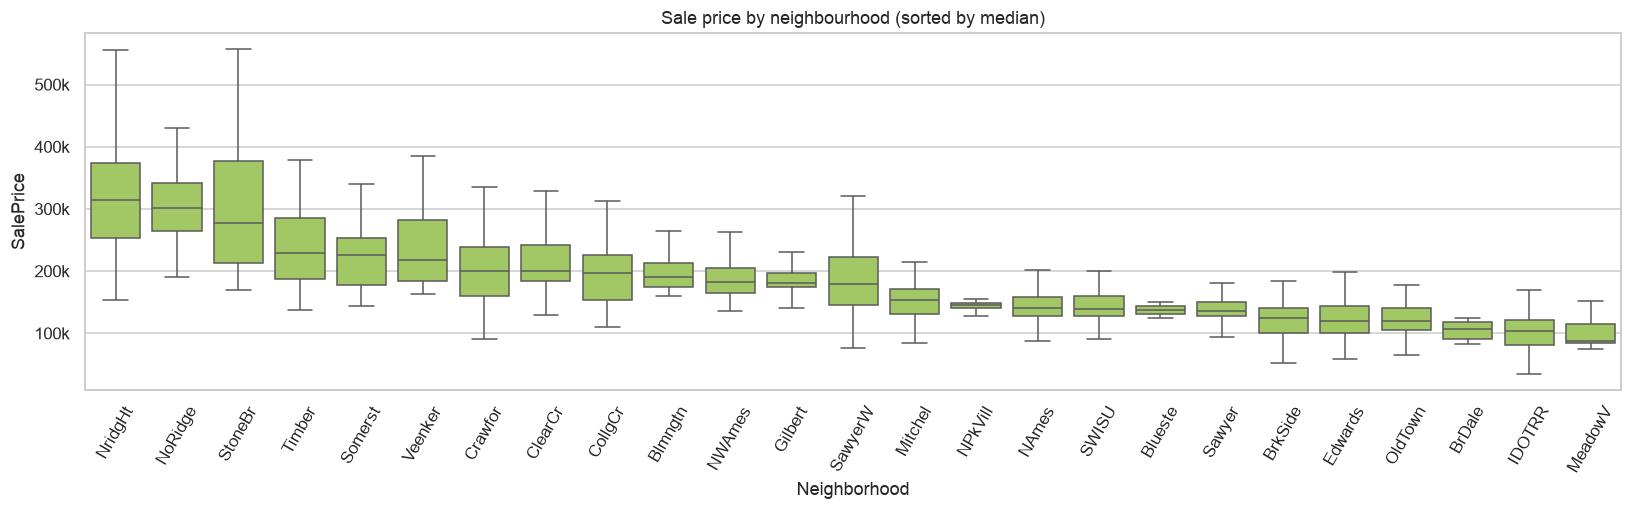

Top 3: {'NridgHt': 315.0, 'NoRidge': 302.0, 'StoneBr': 278.0}  Bottom 3: {'BrDale': 106.0, 'IDOTRR': 103.0, 'MeadowV': 88.0}


In [16]:
nb_order = df_clean.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(15, 4.8))
sns.boxplot(data=df_clean, x="Neighborhood", y="SalePrice", order=nb_order.index, ax=ax, showfliers=False, color="#a6d854")
ax.tick_params(axis="x", rotation=60); ax.set_title("Sale price by neighbourhood (sorted by median)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
plt.tight_layout(); plt.savefig(OUT / "08_neighborhood.png"); plt.show()
print("Top 3:", (nb_order.head(3) / 1000).round(0).to_dict(), " Bottom 3:", (nb_order.tail(3) / 1000).round(0).to_dict())

**Answer: how features relate to price**
1. **Quality is the strongest driver.**
   - `OverallQual` has the highest correlation of any original column (r about 0.82 with log price), and the median price rises at every step from 1 to 10. The relationship is close to exponential.
   - `KitchenQual`, `ExterQual` and `BsmtQual` show the same staircase pattern: "Ex" kitchens have a median of about $318k, against $201k for "Gd" and $137k for "TA".
2. **Size comes next:**
   - `GrLivArea` (r about 0.73)
   - our `TotalSF` (r about 0.82)
   - `GarageCars` / `GarageArea` (r about 0.68 and 0.66)
   - `TotalBsmtSF`
   - `1stFlrSF`

   The scatter coloured by quality band shows that **size and quality multiply**: large houses only command top prices when they are also high quality. This is the rationale for the `Qual_x_*` interaction features.
3. **Age and renovation:** newer houses (`YearBuilt` r about 0.59) and recently remodelled houses (`YearRemodAdd` r about 0.57) sell for more. The trend is flat before about 1950 and climbs steeply after 1980.
4. **Location:** median prices range from about $280-315k (NridgHt, NoRidge, StoneBr) down to about $88-106k (MeadowV, IDOTRR, BrDale). That is a 3x gap for location alone.
5. **Amenities:**
   - Central air: median $168k with it vs $98k without.
   - Fireplaces: median $135k with none, $190k with one.
   - Garage capacity: from $100k with no garage to $295k for 3 cars.
   - The only break in the pattern is 4-car garages (median $200k), and there are just 5 of them.
6. **Weak or no relationship:** `MoSold`, `YrSold`, `LowQualFinSF`, `MiscVal` and `OverallCond` (on its own) barely move the price (|r| < 0.05). `EnclosedPorch` and `KitchenAbvGr` are mildly *negative* (r about -0.15), because they mostly appear in older houses and duplexes.
7. **Multicollinearity:** several pairs carry almost the same information: `GarageCars`/`GarageArea` (0.89), `GrLivArea`/`TotRmsAbvGrd` (0.83) and `TotalBsmtSF`/`1stFlrSF` (0.80). Tree ensembles handle this well, but it is a reason not to read single-feature importances too literally.

## 3.3 Trends and patterns

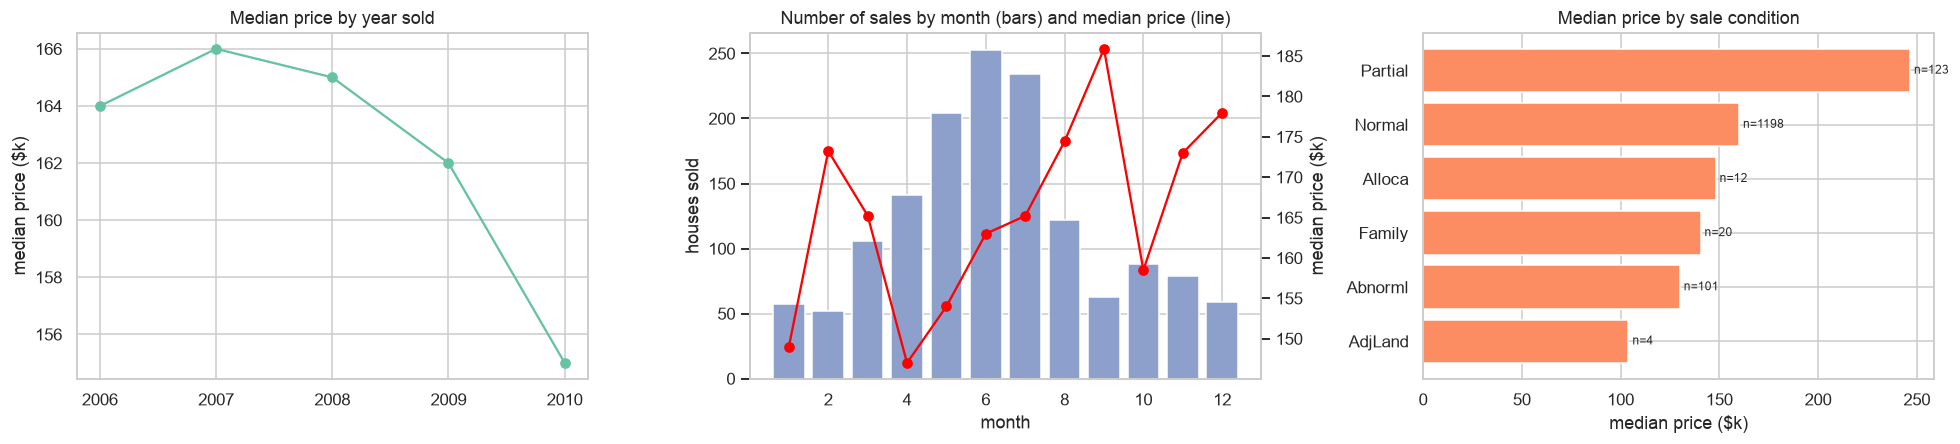

        median  count
YrSold               
2006    163995    314
2007    166000    328
2008    165000    303
2009    162000    338
2010    155000    175


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
yr = df_clean.groupby("YrSold")["SalePrice"].agg(["median", "count"])
axes[0].plot(yr.index, yr["median"] / 1000, marker="o"); axes[0].set_title("Median price by year sold")
axes[0].set_ylabel("median price ($k)"); axes[0].set_xticks(yr.index)
mo = df_clean.groupby("MoSold")["SalePrice"].agg(["median", "count"])
ax2 = axes[1]; ax2.bar(mo.index, mo["count"], color="#8da0cb"); ax2.set_title("Number of sales by month (bars) and median price (line)")
ax2.set_xlabel("month"); ax2.set_ylabel("houses sold"); ax2b = ax2.twinx()
ax2b.plot(mo.index, mo["median"] / 1000, c="red", marker="o"); ax2b.set_ylabel("median price ($k)"); ax2b.grid(False)
sc = df_clean.groupby("SaleCondition")["SalePrice"].agg(["median", "count"]).sort_values("median")
axes[2].barh(sc.index, sc["median"] / 1000, color="#fc8d62"); axes[2].set_title("Median price by sale condition")
for i, (m, n) in enumerate(zip(sc["median"], sc["count"])):
    axes[2].text(m / 1000 + 2, i, f"n={n}", va="center", fontsize=8)
axes[2].set_xlabel("median price ($k)")
plt.tight_layout(); plt.savefig(OUT / "09_trends.png"); plt.show()
print(yr.assign(median=lambda t: t["median"].astype(int)))

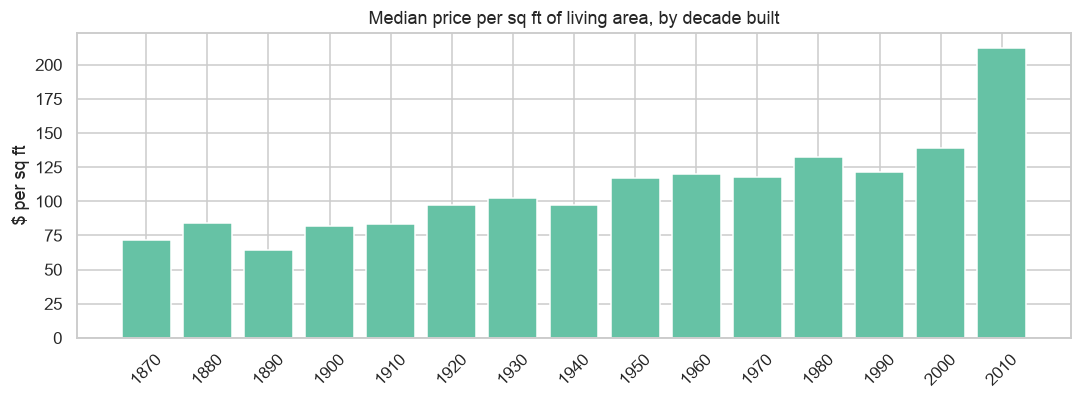

,houses,median_price,median_price_per_sf,median_qual
Decade,,,,
1870,2,108000.0,72.0,6.0
1880,7,124000.0,84.0,6.0
1890,6,142200.0,65.0,6.0
1900,15,127000.0,82.0,5.0
1910,58,128750.0,83.0,5.0
1920,97,115000.0,97.0,5.0
1930,54,126500.0,102.0,6.0
1940,79,122900.0,97.0,5.0
1950,167,136000.0,117.0,5.0


In [18]:
# Price per square foot by decade built - removes the size effect to show pure 'age premium'
d = df_clean.assign(Decade=(df_clean["YearBuilt"] // 10) * 10, PricePerSF=df_clean["SalePrice"] / df_clean["GrLivArea"])
dec = d.groupby("Decade").agg(houses=("Id", "count"), median_price=("SalePrice", "median"),
                              median_price_per_sf=("PricePerSF", "median"), median_qual=("OverallQual", "median"))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(dec.index.astype(str), dec["median_price_per_sf"], color="#66c2a5")
ax.set_title("Median price per sq ft of living area, by decade built"); ax.set_ylabel("$ per sq ft")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(OUT / "10_price_per_sf_decade.png"); plt.show()
dec.round(0)

**Answer: trends and patterns**
- **Little change across years sold.** The median price stays at $162k-$166k from 2006 to 2009, in spite of the 2008 financial crisis, and dips to $155k in 2010, a year that only covers sales up to July. Since time of sale matters little, a random train/test split is reasonable.
- **Seasonality in volume, not price.** Sales peak in **May-July** (204-253 sales a month, against 52-59 in December-February), when families move between school years. The median price hardly changes by month.
- **Sale condition matters.** **Partial** sales (new homes sold before completion) have the highest median, about $247k, because they are new builds. **Abnormal** sales (foreclosures, short sales: $130k) and **AdjLand** sales ($104k) go for much less than Normal sales ($160k).
- **The new-construction premium is real.** Price *per square foot* climbs from about $65-85 for pre-1920 homes to about $118 for 1950s-1970s homes and $139 for homes built in the 2000s. Newer homes are worth more per square foot, not just bigger, partly because they also have higher quality ratings (median 7 vs 5).
- **Quality × size.** The highest prices only appear when good quality and large size come together, which is the pattern the interaction features capture.

# Task 1 (continued): encoding and normalisation

The data is now cleaned and engineered, so the final model matrix can be built.

## 1.2 Converting categorical variables

Three encodings, chosen by the type of each column:

| Type | Columns | Encoding | Why |
|---|---|---|---|
| **Ordered quality/condition scales** | ExterQual, ExterCond, BsmtQual, BsmtCond, HeatingQC, KitchenQual, FireplaceQu, GarageQual, GarageCond, PoolQC | Ex=5 ... Po=1, None=0 | the categories have a clear order, and a number keeps it in a single column |
| **Other ordered scales** | BsmtExposure, BsmtFinType1/2, GarageFinish, Functional, LotShape, LandSlope, PavedDrive, CentralAir, Street, Utilities + the 5 bins | integer by rank | same reasoning |
| **Nominal (no order)** | MSZoning, Neighborhood, MSSubClass, HouseStyle, Exterior1st/2nd, SaleType, ... | **one-hot** | no order exists, so integers would invent a false one |

`MSSubClass` is stored as a number (20, 30, 60...), but it is really a **code for the dwelling type**, so it is converted to text and one-hot encoded.
Rare categories are **not** dropped, but one-hot columns are created from the **training categories only**. A category that appears only in the test set becomes all zeros instead of crashing the model.

In [19]:
ORDINAL_MAPS = {
    **{c: QUAL_MAP for c in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                             "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]},
    "BsmtExposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Functional":   {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "LotShape":     {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "LandSlope":    {"Sev": 0, "Mod": 1, "Gtl": 2},
    "PavedDrive":   {"N": 0, "P": 1, "Y": 2},
    "CentralAir":   {"N": 0, "Y": 1},
    "Street":       {"Grvl": 0, "Pave": 1},
    "Utilities":    {"NoSeWa": 0, "AllPub": 1},
}
BIN_COLS = list(BINS)

def encode(d):
    d = d.drop(columns=["Id"]).copy()
    d["MSSubClass"] = "SC" + d["MSSubClass"].astype(str)          # code, not a quantity
    for c, m in ORDINAL_MAPS.items():
        d[c] = d[c].map(m)
    for c in BIN_COLS:
        d[c] = d[c].cat.codes                                      # ordered bins -> 0,1,2,3
    return d

tr, te = encode(train_df), encode(test_df)
unmapped = [c for c in ORDINAL_MAPS if tr[c].isna().any() or te[c].isna().any()]
print("Ordinal columns with unmapped values:", unmapped or "none")

NOMINAL = tr.select_dtypes("object").columns.tolist()
print(f"{len(ORDINAL_MAPS)} ordinal-encoded, {len(BIN_COLS)} bins, {len(NOMINAL)} one-hot:", NOMINAL)

y_train, y_test = np.log1p(tr.pop("SalePrice")), np.log1p(te.pop("SalePrice"))
X_train = pd.get_dummies(tr, columns=NOMINAL, dtype=int)
X_test = pd.get_dummies(te, columns=NOMINAL, dtype=int).reindex(columns=X_train.columns, fill_value=0)
print("Model matrix:", X_train.shape, X_test.shape)

Ordinal columns with unmapped values: none
21 ordinal-encoded, 5 bins, 23 one-hot: ['MSSubClass', 'MSZoning', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']
Model matrix: (1166, 260) (292, 260)


## 1.3 Normalising numerical features

Two steps, both **fitted on the training set only**:
1. **Log-transform skewed columns.** Numeric columns with |skewness| > 0.75 (areas, lot size, porches and similar) get `log1p`. This pulls in the long right tails that the IQR scan flagged, so a few huge values no longer dominate.
2. **Standardise** every continuous column to mean 0 and standard deviation 1 (z-score) with `StandardScaler`, so all features are on a comparable scale.

One-hot 0/1 columns are left as they are, because scaling a dummy variable adds nothing.
**Note:** tree-based boosting models split on thresholds, so their predictions barely change with scaling. Normalisation matters here for the **Ridge baseline** and for comparing coefficients and features on one scale. The same scaled matrix is used for all models, which keeps the comparison consistent.

In [20]:
onehot_cols = [c for c in X_train.columns if c not in tr.columns]
cont_cols = [c for c in X_train.columns if c not in onehot_cols and X_train[c].nunique() > 2]

skewness = X_train[cont_cols].skew()
skewed = skewness[skewness.abs() > 0.75].index.tolist()
skewed = [c for c in skewed if (X_train[c] >= 0).all()]       # log1p needs non-negative values
print(f"{len(skewed)} skewed columns get log1p, e.g.", skewed[:8])

X_train_n, X_test_n = X_train.copy().astype(float), X_test.copy().astype(float)
X_train_n[skewed] = np.log1p(X_train_n[skewed]); X_test_n[skewed] = np.log1p(X_test_n[skewed].clip(lower=0))

scaler = StandardScaler().fit(X_train_n[cont_cols])
X_train_n[cont_cols] = scaler.transform(X_train_n[cont_cols])
X_test_n[cont_cols] = scaler.transform(X_test_n[cont_cols])

before_after = pd.DataFrame({"skew before": X_train[skewed].skew(), "skew after log": np.log1p(X_train[skewed]).skew()}).round(2)
print(X_train_n[cont_cols].describe().loc[["mean", "std"]].T.round(2).head(6))
before_after.sort_values("skew before", ascending=False).head(10)

39 skewed columns get log1p, e.g. ['LotFrontage', 'LotArea', 'LotShape', 'LandSlope', 'MasVnrArea', 'ExterQual', 'ExterCond', 'BsmtQual']


             mean  std
LotFrontage  -0.0  1.0
LotArea      -0.0  1.0
LotShape      0.0  1.0
LandSlope     0.0  1.0
OverallQual  -0.0  1.0
OverallCond  -0.0  1.0


,skew before,skew after log
MiscVal,22.42,4.96
PoolQC,17.64,16.13
PoolArea,15.69,15.20
LotArea,12.30,-0.03
LowQualFinSF,9.96,7.86
3SsnPorch,9.73,7.20
LotArea_per_SF,9.01,0.83
KitchenAbvGr,4.34,4.23
ScreenPorch,4.09,3.06
BsmtFinSF2,4.04,2.42


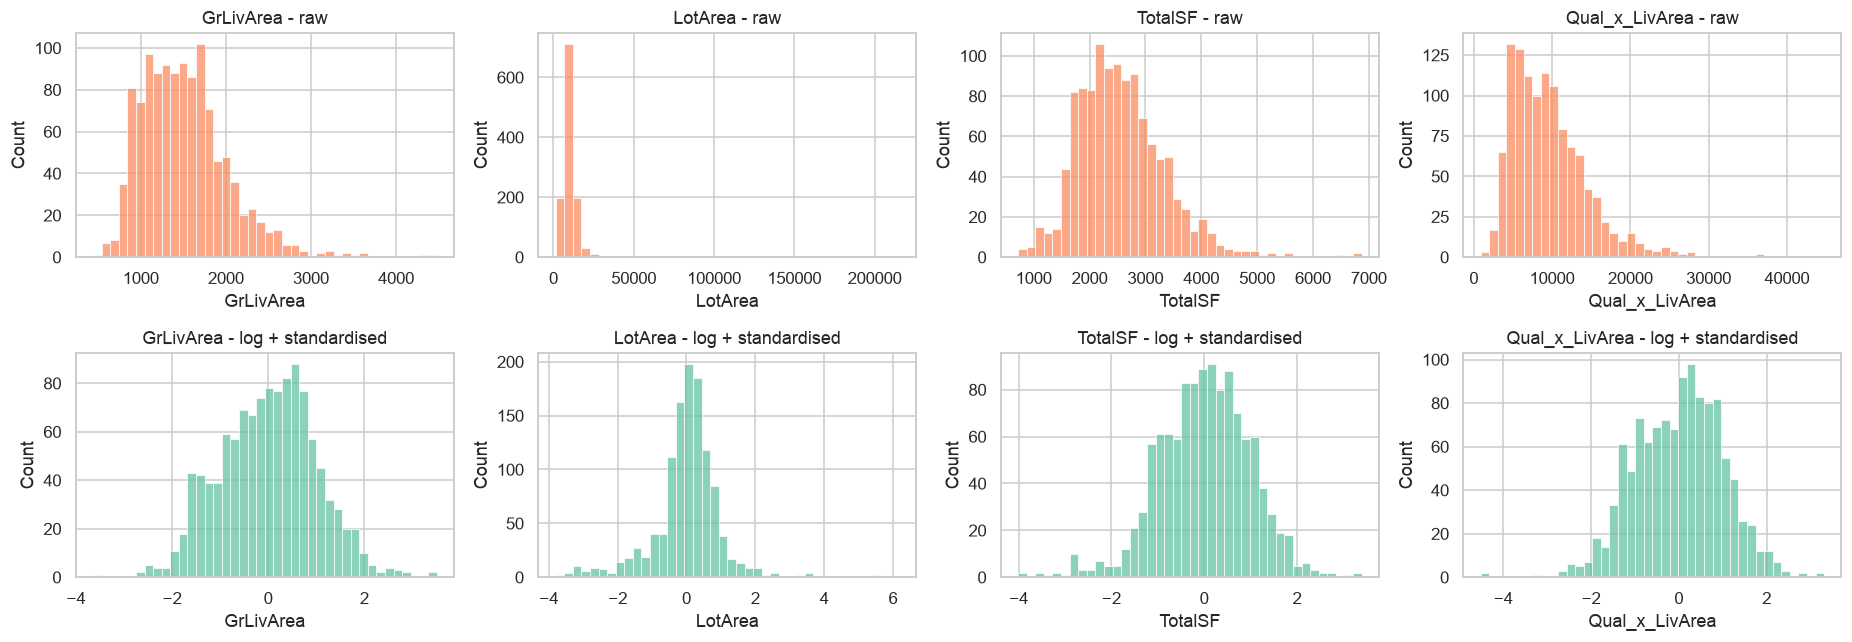

In [21]:
show = ["GrLivArea", "LotArea", "TotalSF", "Qual_x_LivArea"]
fig, axes = plt.subplots(2, 4, figsize=(17, 6))
for i, c in enumerate(show):
    sns.histplot(X_train[c], bins=40, ax=axes[0, i], color="#fc8d62"); axes[0, i].set_title(f"{c} - raw")
    sns.histplot(X_train_n[c], bins=40, ax=axes[1, i], color="#66c2a5"); axes[1, i].set_title(f"{c} - log + standardised")
plt.tight_layout(); plt.savefig(OUT / "11_normalisation.png"); plt.show()

# Task 4: Model building and evaluation

**Setup**
- **Target:** log(1 + SalePrice). Predictions are converted back to dollars for the business metrics.
- **Validation:** 5-fold cross-validation on the training set (1,166 houses) for tuning. The final metrics come from the untouched **test set** (292 houses).
- **Models:** XGBoost, LightGBM and CatBoost, as required. A **Ridge regression** baseline shows how much the boosting ensembles add.
- **Tuning:** `RandomizedSearchCV` (25 random combinations × 5 folds) over the parameters that matter most for boosting: the number of trees and the learning rate (how fast it learns), tree depth / leaves (complexity), subsampling of rows and columns (adds randomness to fight overfitting), and L1/L2 regularisation.

In [22]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def metrics(y_true_log, y_pred_log):
    """RMSE / MAE in dollars, R² in dollars, and RMSE on the log scale."""
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {"RMSE ($)": mean_squared_error(yt, yp) ** 0.5, "MAE ($)": mean_absolute_error(yt, yp),
            "R²": r2_score(yt, yp), "RMSE (log)": mean_squared_error(y_true_log, y_pred_log) ** 0.5,
            "MAPE (%)": np.mean(np.abs(yp - yt) / yt) * 100}

search_spaces = {
    "XGBoost": (XGBRegressor(random_state=SEED, n_jobs=-1, tree_method="hist"), {
        "n_estimators": [600, 1000, 1500], "learning_rate": [0.02, 0.03, 0.05],
        "max_depth": [3, 4, 5], "min_child_weight": [1, 2, 4], "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.3, 0.5, 0.7], "reg_alpha": [0, 0.001, 0.01], "reg_lambda": [0.5, 1, 3]}),
    "LightGBM": (LGBMRegressor(random_state=SEED, n_jobs=-1, verbose=-1), {
        "n_estimators": [600, 1000, 1500], "learning_rate": [0.02, 0.03, 0.05],
        "num_leaves": [8, 16, 31], "min_child_samples": [5, 10, 20], "subsample": [0.7, 0.8, 1.0],
        "subsample_freq": [1], "colsample_bytree": [0.3, 0.5, 0.7], "reg_alpha": [0, 0.01, 0.1], "reg_lambda": [0, 1, 3]}),
    "CatBoost": (CatBoostRegressor(random_seed=SEED, verbose=0, thread_count=-1), {
        "iterations": [800, 1500], "learning_rate": [0.03, 0.05], "depth": [4, 5, 6],
        "l2_leaf_reg": [1, 3, 5], "rsm": [0.3, 0.5, 1.0], "subsample": [0.7, 0.8], "bootstrap_type": ["Bernoulli"]}),
}

best_models, cv_rows = {}, []
for name, (est, grid) in search_spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(est, grid, n_iter=25, cv=cv, scoring="neg_root_mean_squared_error",
                            random_state=SEED, n_jobs=1 if name == "CatBoost" else 2)
    rs.fit(X_train_n, y_train)
    best_models[name] = rs.best_estimator_
    i = rs.best_index_
    cv_rows.append({"Model": name, "CV RMSE (log)": -rs.cv_results_["mean_test_score"][i],
                    "CV std": rs.cv_results_["std_test_score"][i], "Tuning time (s)": round(time.time() - t0)})
    print(f"{name:9s} CV RMSE(log) = {-rs.best_score_:.4f}  ({time.time()-t0:.0f}s)  best: {rs.best_params_}")

XGBoost   CV RMSE(log) = 0.1108  (80s)  best: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0.001, 'n_estimators': 1000, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.3}


LightGBM  CV RMSE(log) = 0.1127  (326s)  best: {'subsample_freq': 1, 'subsample': 0.7, 'reg_lambda': 1, 'reg_alpha': 0, 'num_leaves': 8, 'n_estimators': 600, 'min_child_samples': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.5}


CatBoost  CV RMSE(log) = 0.1089  (193s)  best: {'subsample': 0.7, 'rsm': 0.3, 'learning_rate': 0.05, 'l2_leaf_reg': 5, 'iterations': 1500, 'depth': 4, 'bootstrap_type': 'Bernoulli'}


In [23]:
# Linear baseline: Ridge regression with built-in CV over the regularisation strength
ridge = RidgeCV(alphas=np.logspace(-1, 3, 30)).fit(X_train_n, y_train)
r_cv = -cross_val_score(RidgeCV(alphas=np.logspace(-1, 3, 30)), X_train_n, y_train, cv=cv,
                        scoring="neg_root_mean_squared_error")
best_models["Ridge (baseline)"] = ridge
cv_rows.append({"Model": "Ridge (baseline)", "CV RMSE (log)": r_cv.mean(), "CV std": r_cv.std(), "Tuning time (s)": 0})
print(f"Ridge alpha = {ridge.alpha_:.1f}, CV RMSE(log) = {r_cv.mean():.4f}")

cv_tbl = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_tbl.to_csv(OUT / "cv_results.csv")
cv_tbl

Ridge alpha = 11.7, CV RMSE(log) = 0.1146


,CV RMSE (log),CV std,Tuning time (s)
Model,,,
XGBoost,0.1108,0.0115,80
LightGBM,0.1127,0.0105,326
CatBoost,0.1089,0.0102,193
Ridge (baseline),0.1146,0.0088,0


## 4.1 Evaluation on the held-out test set

In [24]:
preds = {name: m.predict(X_test_n) for name, m in best_models.items()}
# Simple average of the three boosting models - often more robust than any single one
preds["Average of 3 boosters"] = np.mean([preds["XGBoost"], preds["LightGBM"], preds["CatBoost"]], axis=0)

test_tbl = pd.DataFrame({n: metrics(y_test, p) for n, p in preds.items()}).T
test_tbl = test_tbl.sort_values("RMSE (log)")
test_tbl.round({"RMSE ($)": 0, "MAE ($)": 0, "R²": 4, "RMSE (log)": 4, "MAPE (%)": 2}).to_csv(OUT / "test_results.csv")
test_tbl.style.format({"RMSE ($)": "{:,.0f}", "MAE ($)": "{:,.0f}", "R²": "{:.4f}", "RMSE (log)": "{:.4f}", "MAPE (%)": "{:.2f}"})

,RMSE ($),MAE ($),R²,RMSE (log),MAPE (%)
CatBoost,"18,205","13,087",0.9400,0.1100,7.86
Average of 3 boosters,"18,528","13,319",0.9379,0.1126,8.05
Ridge (baseline),"19,088","13,775",0.9340,0.1139,8.21
XGBoost,"19,427","13,969",0.9317,0.1147,8.32
LightGBM,"19,297","13,634",0.9326,0.1177,8.32


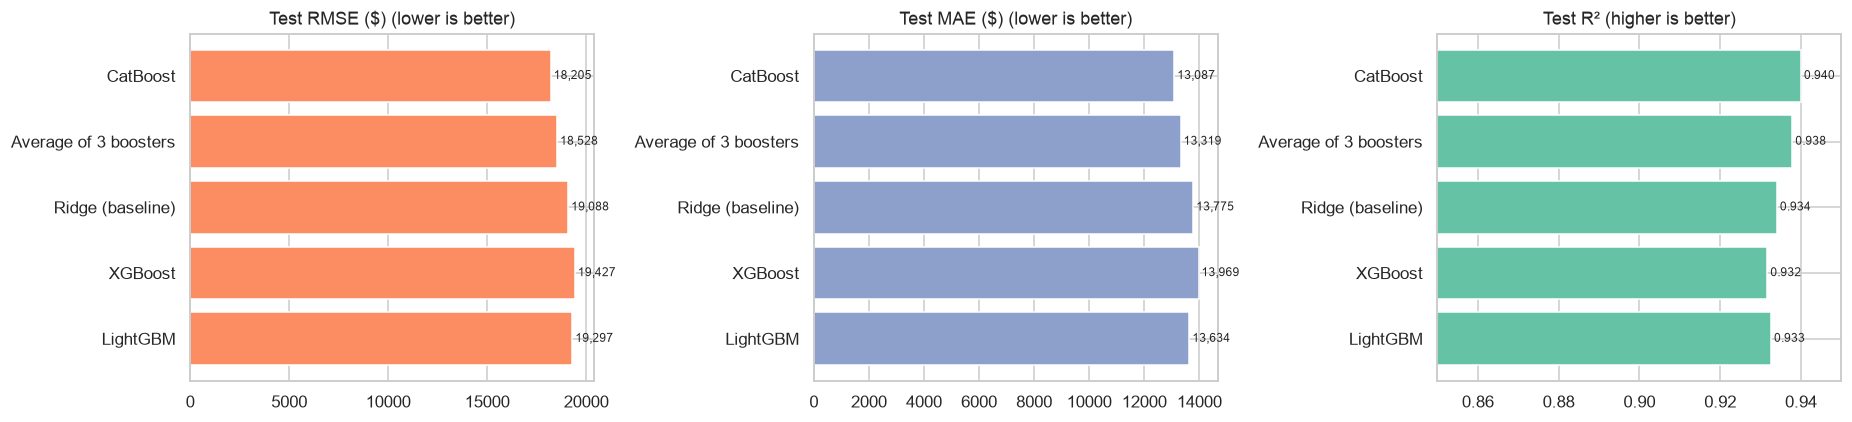

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
order = test_tbl.index
for ax, m, c in zip(axes, ["RMSE ($)", "MAE ($)", "R²"], ["#fc8d62", "#8da0cb", "#66c2a5"]):
    ax.barh(order, test_tbl[m], color=c); ax.invert_yaxis(); ax.set_title(f"Test {m} (lower is better)" if m != "R²" else "Test R² (higher is better)")
    for i, v in enumerate(test_tbl[m]):
        ax.text(v, i, f" {v:,.0f}" if m != "R²" else f" {v:.3f}", va="center", fontsize=8)
    if m == "R²": ax.set_xlim(0.85, 0.95)
plt.tight_layout(); plt.savefig(OUT / "12_model_comparison.png"); plt.show()

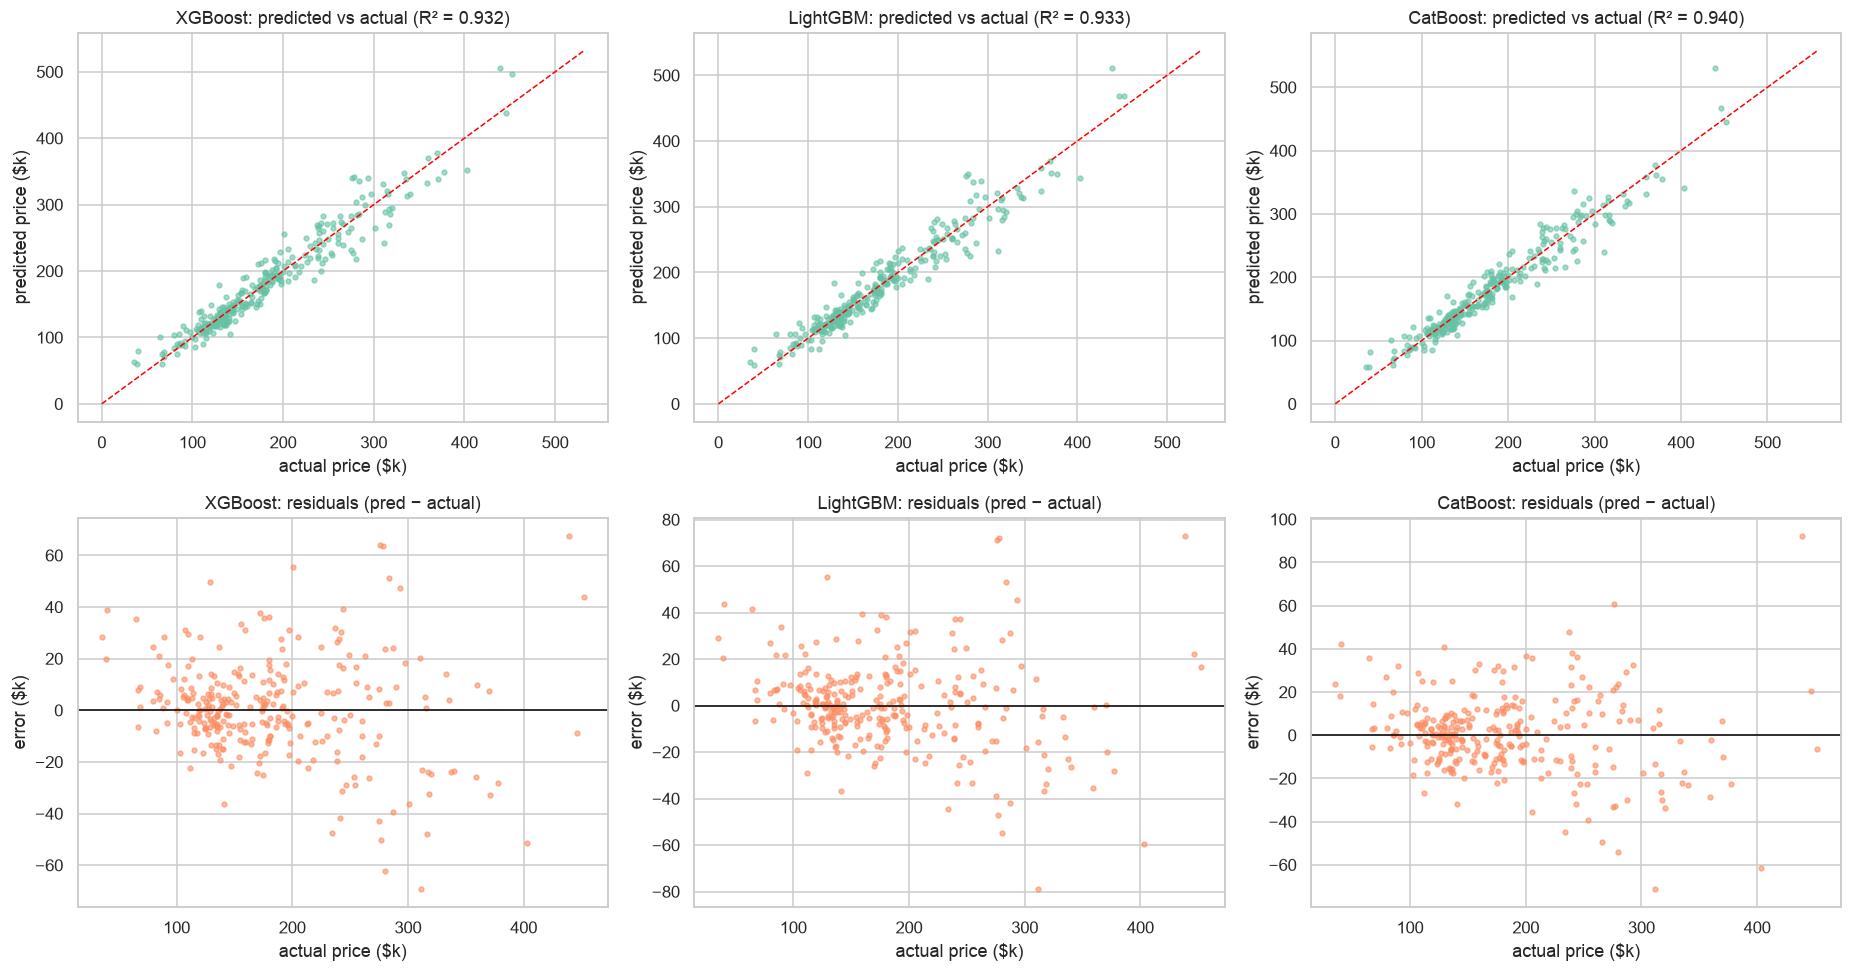

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, name in enumerate(["XGBoost", "LightGBM", "CatBoost"]):
    yt, yp = np.expm1(y_test), np.expm1(preds[name])
    ax = axes[0, i]; ax.scatter(yt / 1000, yp / 1000, s=10, alpha=.6)
    lim = [0, max(yt.max(), yp.max()) / 1000 * 1.05]; ax.plot(lim, lim, "r--", lw=1)
    ax.set_title(f"{name}: predicted vs actual (R² = {r2_score(yt, yp):.3f})")
    ax.set_xlabel("actual price ($k)"); ax.set_ylabel("predicted price ($k)")
    ax = axes[1, i]; res = yp - yt
    ax.scatter(yt / 1000, res / 1000, s=10, alpha=.6, c="#fc8d62"); ax.axhline(0, c="k", lw=1)
    ax.set_title(f"{name}: residuals (pred − actual)"); ax.set_xlabel("actual price ($k)"); ax.set_ylabel("error ($k)")
plt.tight_layout(); plt.savefig(OUT / "13_pred_vs_actual.png"); plt.show()

In [27]:
# Where do the models make their biggest mistakes? (CatBoost shown)
err = pd.DataFrame({"actual": np.expm1(y_test), "predicted": np.expm1(preds["CatBoost"])}, index=y_test.index)
err["abs_err"] = (err["predicted"] - err["actual"]).abs()
err = err.join(test_df[["Neighborhood", "OverallQual", "GrLivArea", "SaleCondition"]])
seg = err.assign(PriceBand=pd.qcut(err["actual"], 4, labels=["<25%", "25-50%", "50-75%", ">75%"])) \
        .groupby("PriceBand", observed=True).apply(lambda g: pd.Series({"houses": len(g), "MAE ($)": g["abs_err"].mean(),
                                                         "MAPE (%)": (g["abs_err"] / g["actual"]).mean() * 100}))
print(seg.round(1))
err.sort_values("abs_err", ascending=False).head(5).round(0)

           houses  MAE ($)  MAPE (%)
PriceBand                           
<25%         73.0   9665.3      11.4
25-50%       73.0   8729.4       6.0
50-75%       73.0  11492.2       6.1
>75%         73.0  22461.9       7.9


,actual,predicted,abs_err,Neighborhood,OverallQual,GrLivArea,SaleCondition
58,438780.0,531096.0,92316.0,StoneBr,10,2945,Partial
218,311500.0,240309.0,71191.0,Crawfor,7,1954,Normal
231,403000.0,341543.0,61457.0,NoRidge,8,2794,Normal
261,276000.0,336677.0,60677.0,CollgCr,8,2574,Partial
451,280000.0,226065.0,53935.0,ClearCr,7,1533,Normal


## 4.2 Do the interaction features help? (ablation test)

The rubric asks for interaction features that *improve model performance*. To test this, each booster is re-run with its tuned parameters under 5-fold CV on the training set, twice:
- **without** the 17 interaction features (original columns + bins only)
- **with** them

In [28]:
no_inter = [c for c in X_train_n.columns if c not in INTERACTIONS]
abl_rows = []
for name in ["XGBoost", "LightGBM", "CatBoost", "Ridge (baseline)"]:
    m = best_models[name]
    without = -cross_val_score(m, X_train_n[no_inter], y_train, cv=cv, scoring="neg_root_mean_squared_error")
    with_ = -cross_val_score(m, X_train_n, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    abl_rows.append({"Model": name, "CV RMSE without interactions": without.mean(),
                     "CV RMSE with interactions": with_.mean(),
                     "Improvement (%)": (without.mean() - with_.mean()) / without.mean() * 100,
                     "Folds improved": f"{int((with_ < without).sum())}/5"})
abl = pd.DataFrame(abl_rows).set_index("Model").round(4)
abl.to_csv(OUT / "ablation_interactions.csv")
abl

,CV RMSE without interactions,CV RMSE with interactions,Improvement (%),Folds improved
Model,,,,
XGBoost,0.1146,0.1108,3.3246,5/5
LightGBM,0.1174,0.1127,3.9887,5/5
CatBoost,0.1116,0.1089,2.4620,5/5
Ridge (baseline),0.1144,0.1146,-0.1698,2/5


## 4.3 What drives the predictions? (feature importance)

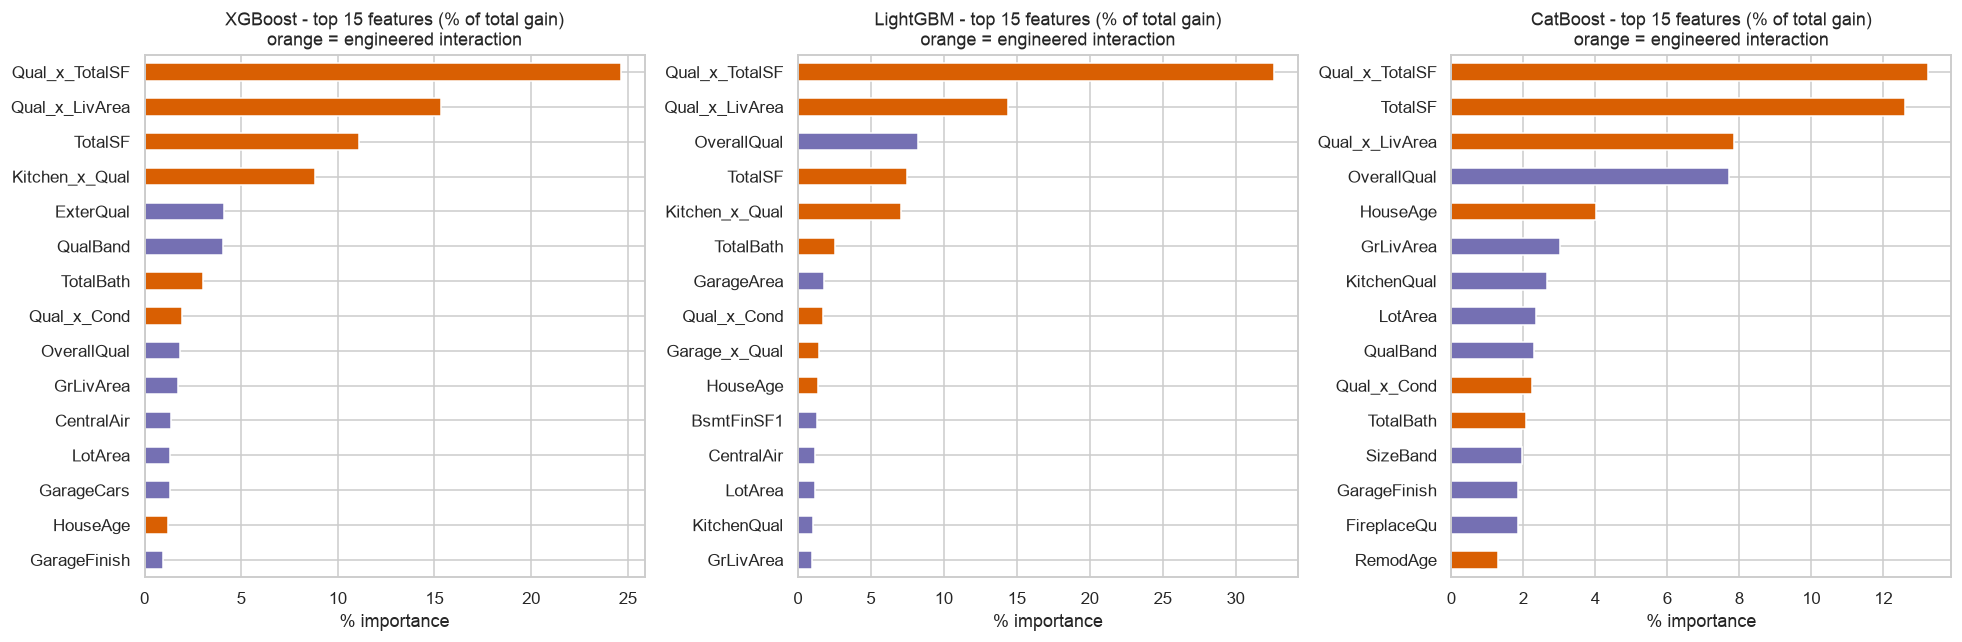

,XGBoost,LightGBM,CatBoost
BsmtFinSF1,,1.3,
CentralAir,1.4,1.2,
ExterQual,4.1,,
FireplaceQu,,,1.8
GarageArea,,1.8,
GarageCars,1.3,,
GarageFinish,1.0,,1.9
Garage_x_Qual,,1.5,
GrLivArea,1.8,1.0,3.0
HouseAge,1.2,1.4,4.0


In [29]:
def top_imp(model, n=15):
    if hasattr(model, "get_feature_importance"):          # CatBoost
        imp = model.get_feature_importance()
    elif isinstance(model, XGBRegressor):                  # XGBoost: total gain
        g = model.get_booster().get_score(importance_type="total_gain")
        imp = np.array([g.get(c, 0) for c in X_train_n.columns])
    else:                                                  # LightGBM: total gain
        imp = model.booster_.feature_importance(importance_type="gain")
    s = pd.Series(imp, index=X_train_n.columns)
    return (s / s.sum() * 100).sort_values(ascending=False).head(n)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
imps = {}
for ax, name in zip(axes, ["XGBoost", "LightGBM", "CatBoost"]):
    s = top_imp(best_models[name]); imps[name] = s
    s[::-1].plot.barh(ax=ax, color=["#d95f02" if c in INTERACTIONS else "#7570b3" for c in s.index[::-1]])
    ax.set_title(f"{name} - top 15 features (% of total gain)\norange = engineered interaction"); ax.set_xlabel("% importance")
plt.tight_layout(); plt.savefig(OUT / "14_feature_importance.png"); plt.show()

imp_tbl = pd.DataFrame({n: s.round(1) for n, s in imps.items()}).fillna("")
imp_tbl.to_csv(OUT / "feature_importance.csv")
imp_tbl

# Conclusions

**Data preparation**
- 19 columns had missing values. They were filled using the "facility absent" rule ("None" for categories, 0 for the matching numeric fields), with three genuine gaps filled by the mode and `LotFrontage` filled by the neighbourhood median.
- Two anomalous partial sales were removed. Skew in the other outliers was handled with log transforms.
- 21 ordered columns were integer-encoded, 23 nominal columns were one-hot encoded, and all continuous columns were standardised. The final model matrix has 260 columns.

**Feature engineering**
- 17 interaction features were added. The quality × size interactions are the most correlated with price (r = 0.88) and the most important features in all three models.
- Removing the interactions makes every booster worse: CV RMSE rises by 2.5-4.0%, and in **5 of 5 folds** for each model. So the interactions measurably improve performance.
- 5 binned features (age, quality, size, era and lot bands) give clearly separated price levels.

**What drives price**
1. Overall quality, especially combined with size
2. Total living area including the basement
3. Kitchen, exterior and basement quality
4. House age and remodelling
5. Neighbourhood (a 3x spread)
6. Garage capacity and quality
7. Number of bathrooms

The time of sale (month or year) barely matters.

**Models**
- All three boosters were tuned with 25-combination randomised search and 5-fold CV.
- **CatBoost** was best on both CV (RMSE 0.109 on log price) and the held-out test set: **RMSE about $18.2k, MAE about $13.1k, R² = 0.940**, typical error about 7.9% of the price.
- XGBoost and LightGBM came close (R² about 0.932-0.933).
- Errors are largest in dollars for the most expensive quartile (MAE about $22k), but in percentage terms they are similar across price bands (6-11%), with the cheapest homes hardest in relative terms.
- The well-regularised Ridge baseline also scores R² 0.934 on the test set. With good engineered features and a log target, much of the signal is close to linear. All the differences between models are within about 1 CV standard deviation (about 0.01 log RMSE), so CatBoost's lead is real but small.

**Limitations and next steps**
- Only 1,458 houses from one city (Ames, Iowa, 2006-2010), so the model should not be applied to other markets without retraining.
- Possible next steps: stack the boosters with the Ridge model, try CatBoost's native categorical handling instead of one-hot, and add SHAP plots to explain individual predictions.